## 1. Setup

### 1.1 Shared helper module
This cell writes `real_estate_utils.py` - it is imported here **and** by the Streamlit app so feature engineering is identical in training and inference.

In [1]:
%%writefile real_estate_utils.py
"""Shared helpers for the Real Estate Investment Advisor project.

Used by BOTH the Jupyter notebook (training) and the Streamlit app (inference),
so the features are always built identically.
"""
import numpy as np
import pandas as pd

# --------------------------------------------------------------------------- #
# Constants
# --------------------------------------------------------------------------- #
CURRENT_YEAR = 2025
HORIZON_YEARS = 5
BASE_GROWTH_RATE = 0.08            # fixed-rate baseline: Future = Current * (1 + r) ** t
GOOD_INVESTMENT_THRESHOLD = 4      # multi-factor score (0-7) >= threshold -> Good Investment
TRANSPORT_MAP = {"low": 1, "medium": 2, "high": 3}
NEG_VALUES = {"no", "none", "n", "false", "0", "0.0", "nan", "", "na", "null"}

NUM_FEATURES = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Age_of_Property",
    "Floor_No", "Total_Floors", "Floor_Ratio", "Nearby_Schools", "Nearby_Hospitals",
    "Parking_Flag", "Security_Flag", "Amenity_Count", "Transport_Score", "Is_Ready",
    "School_Density_Score", "Hospital_Score", "Infrastructure_Score",
    "City_Median_PPSF", "PPSF_vs_City",
]
CAT_FEATURES = [
    "State", "City", "Property_Type", "Furnished_Status", "Facing",
    "Owner_Type", "Availability_Status",
]
ALL_FEATURES = NUM_FEATURES + CAT_FEATURES

RAW_NUMERIC_COLS = [
    "BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Year_Built",
    "Floor_No", "Total_Floors", "Age_of_Property", "Nearby_Schools", "Nearby_Hospitals",
]


# --------------------------------------------------------------------------- #
# Small utilities
# --------------------------------------------------------------------------- #
def to_binary(s: pd.Series) -> pd.Series:
    """Turn Yes/No, True/False, 0/1 or counts (>0) into a 0/1 flag."""
    s = pd.Series(s)
    num = pd.to_numeric(s, errors="coerce")
    text_flag = ~s.astype(str).str.strip().str.lower().isin(NEG_VALUES)
    out = np.where(num.notna(), num > 0, text_flag)
    return pd.Series(out.astype(int), index=s.index)


def count_amenities(x) -> int:
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return 0
    return len([a for a in str(x).split(",") if a.strip()])


# --------------------------------------------------------------------------- #
# Cleaning
# --------------------------------------------------------------------------- #
def basic_clean(df: pd.DataFrame) -> pd.DataFrame:
    """Strip text, drop duplicates, fix types, impute missing values."""
    d = df.copy()
    d.columns = d.columns.str.strip()

    text_cols = [c for c in d.columns if not pd.api.types.is_numeric_dtype(d[c])]
    for c in text_cols:
        d[c] = d[c].astype(str).str.strip().replace({"nan": np.nan, "None": np.nan, "": np.nan})

    # duplicates (ignore the ID column, which is unique by construction)
    subset = [c for c in d.columns if c != "ID"]
    d = d.drop_duplicates(subset=subset).reset_index(drop=True)

    for c in RAW_NUMERIC_COLS:
        if c in d.columns:
            d[c] = pd.to_numeric(d[c], errors="coerce")

    # price and size are essential: drop rows where they are missing / invalid
    d = d.dropna(subset=["Size_in_SqFt", "Price_in_Lakhs"])
    d = d[(d["Size_in_SqFt"] > 0) & (d["Price_in_Lakhs"] > 0)].reset_index(drop=True)

    # impute: numeric -> median, categorical -> mode
    for c in RAW_NUMERIC_COLS:
        if c in d.columns and d[c].isna().any():
            d[c] = d[c].fillna(d[c].median())
    for c in text_cols:
        if c != "ID" and d[c].isna().any():
            mode = d[c].mode(dropna=True)
            d[c] = d[c].fillna(mode.iloc[0] if len(mode) else "Unknown")

    # consistency fixes
    d["Age_of_Property"] = (CURRENT_YEAR - d["Year_Built"]).clip(lower=0)
    d["Total_Floors"] = np.maximum(d["Total_Floors"], d["Floor_No"])
    d["Price_per_SqFt"] = d["Price_in_Lakhs"] * 1e5 / d["Size_in_SqFt"]   # Rs per sq ft
    return d


def iqr_bounds(s: pd.Series, k: float = 1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def cap_outliers(df: pd.DataFrame, cols=("Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt"), k: float = 3.0):
    """Winsorise extreme values with an IQR rule (keeps all rows)."""
    d = df.copy()
    bounds = {}
    for c in cols:
        lo, hi = iqr_bounds(d[c], k)
        lo = max(lo, d[c].min())
        bounds[c] = (float(lo), float(hi))
        d[c] = d[c].clip(lo, hi)
    d["Price_per_SqFt"] = d["Price_in_Lakhs"] * 1e5 / d["Size_in_SqFt"]
    return d, bounds


# --------------------------------------------------------------------------- #
# Meta (statistics learned from training data, reused at inference time)
# --------------------------------------------------------------------------- #
def fit_meta(df: pd.DataFrame) -> dict:
    d = df
    city_ppsf = d.groupby("City")["Price_per_SqFt"].median()
    rank_pct = city_ppsf.rank(pct=True)
    amen_counts = d["Amenities"].apply(count_amenities)
    amen_items = (
        d["Amenities"].dropna().astype(str).str.split(",").explode().str.strip()
    )
    meta = {
        "current_year": CURRENT_YEAR,
        "global_median_ppsf": float(d["Price_per_SqFt"].median()),
        "global_median_price": float(d["Price_in_Lakhs"].median()),
        "city_median_ppsf": {k: float(v) for k, v in city_ppsf.items()},
        "city_type_median_price": {
            f"{c}|{t}": float(v)
            for (c, t), v in d.groupby(["City", "Property_Type"])["Price_in_Lakhs"].median().items()
        },
        # costlier cities get slightly higher growth, cheaper ones slightly lower (+/-1%)
        "city_growth_adj": {k: float((v - 0.5) * 0.02) for k, v in rank_pct.items()},
        "schools_max": float(max(d["Nearby_Schools"].max(), 1)),
        "hospitals_max": float(max(d["Nearby_Hospitals"].max(), 1)),
        "amenity_max": float(max(amen_counts.max(), 1)),
        "city_state": d.drop_duplicates("City").set_index("City")["State"].to_dict(),
        "amenity_options": sorted(amen_items[amen_items != ""].unique().tolist()),
        "transport_options": sorted(d["Public_Transport_Accessibility"].dropna().unique().tolist()),
        "categories": {c: sorted(d[c].dropna().unique().tolist()) for c in CAT_FEATURES},
        "ranges": {
            "size": [float(d["Size_in_SqFt"].min()), float(d["Size_in_SqFt"].max())],
            "price": [float(d["Price_in_Lakhs"].min()), float(d["Price_in_Lakhs"].max())],
            "year_built": [int(d["Year_Built"].min()), int(d["Year_Built"].max())],
            "bhk": [int(d["BHK"].min()), int(d["BHK"].max())],
            "floors": [int(d["Total_Floors"].max())],
            "schools_median": float(d["Nearby_Schools"].median()),
            "hospitals_median": float(d["Nearby_Hospitals"].median()),
        },
    }
    return meta


# --------------------------------------------------------------------------- #
# Feature engineering
# --------------------------------------------------------------------------- #
def engineer_features(df: pd.DataFrame, meta: dict) -> pd.DataFrame:
    d = df.copy()
    d["Transport_Score"] = (
        d["Public_Transport_Accessibility"].astype(str).str.strip().str.lower().map(TRANSPORT_MAP).fillna(2)
    )
    d["Parking_Flag"] = to_binary(d["Parking_Space"])
    d["Security_Flag"] = to_binary(d["Security"])
    d["Amenity_Count"] = d["Amenities"].apply(count_amenities)
    d["Is_Ready"] = d["Availability_Status"].astype(str).str.lower().str.contains("ready").astype(int)
    d["Floor_Ratio"] = d["Floor_No"] / d["Total_Floors"].replace(0, np.nan)
    d["Floor_Ratio"] = d["Floor_Ratio"].fillna(0)

    d["School_Density_Score"] = (d["Nearby_Schools"] / meta["schools_max"]).clip(0, 1)
    d["Hospital_Score"] = (d["Nearby_Hospitals"] / meta["hospitals_max"]).clip(0, 1)
    d["Infrastructure_Score"] = (
        d["School_Density_Score"]
        + d["Hospital_Score"]
        + d["Transport_Score"] / 3
        + (d["Amenity_Count"] / meta["amenity_max"]).clip(0, 1)
        + d["Parking_Flag"]
        + d["Security_Flag"]
    ) / 6

    d["City_Median_PPSF"] = d["City"].map(meta["city_median_ppsf"]).fillna(meta["global_median_ppsf"])
    d["PPSF_vs_City"] = d["Price_per_SqFt"] / d["City_Median_PPSF"]
    return d


# --------------------------------------------------------------------------- #
# Target creation (domain rules)
# --------------------------------------------------------------------------- #
def make_targets(df: pd.DataFrame, meta: dict, seed: int = 42) -> pd.DataFrame:
    """Create 'Good_Investment' (classification) and 'Future_Price_5Y_Lakhs' (regression)."""
    d = df.copy()
    rng = np.random.default_rng(seed)

    # ---- Classification: multi-factor score (max 7) ------------------------
    meta["infra_median"] = float(d["Infrastructure_Score"].median())
    city_type_med = np.array([
        meta["city_type_median_price"].get(f"{c}|{t}", meta["global_median_price"])
        for c, t in zip(d["City"], d["Property_Type"])
    ])
    d["Investment_Score"] = (
        2 * (d["Price_per_SqFt"] <= d["City_Median_PPSF"]).astype(int)    # cheaper per sqft than city median
        + (d["Price_in_Lakhs"] <= city_type_med).astype(int)             # cheaper than city/type median price
        + (d["BHK"] >= 3).astype(int)
        + d["Is_Ready"]
        + (d["Transport_Score"] >= 2).astype(int)
        + (d["Infrastructure_Score"] >= meta["infra_median"]).astype(int)
    )
    d["Good_Investment"] = (d["Investment_Score"] >= GOOD_INVESTMENT_THRESHOLD).astype(int)

    # ---- Regression: feature-based annual growth rate ----------------------
    city_adj = d["City"].map(meta["city_growth_adj"]).fillna(0.0)
    rate = (
        BASE_GROWTH_RATE
        + 0.010 * (d["Transport_Score"] - 2)
        + 0.030 * (d["Infrastructure_Score"] - 0.5)
        + 0.005 * d["Is_Ready"]
        + city_adj
        + rng.normal(0, 0.004, len(d))
    ).clip(0.03, 0.15)
    d["Annual_Growth_Rate"] = rate
    d["Future_Price_5Y_Lakhs"] = d["Price_in_Lakhs"] * (1 + rate) ** HORIZON_YEARS
    return d

Writing real_estate_utils.py


In [2]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import mlflow, mlflow.sklearn

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)
from xgboost import XGBClassifier, XGBRegressor

from real_estate_utils import *

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = "india_housing_prices.csv"
RANDOM_STATE = 42
os.makedirs("data", exist_ok=True)
os.makedirs("models", exist_ok=True)

C:\Users\Dell\anaconda3\envs\ml_env\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.3)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


## 2. Load & Inspect Data

In [4]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (250000, 23)


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,0.10,1990,Furnished,22,1,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,0.08,2008,Unfurnished,21,20,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,0.05,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,0.11,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,0.04,2002,Semi-furnished,3,2,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


In [5]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 23 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   ID                              250000 non-null  int64  
 1   State                           250000 non-null  object 
 2   City                            250000 non-null  object 
 3   Locality                        250000 non-null  object 
 4   Property_Type                   250000 non-null  object 
 5   BHK                             250000 non-null  int64  
 6   Size_in_SqFt                    250000 non-null  int64  
 7   Price_in_Lakhs                  250000 non-null  float64
 8   Price_per_SqFt                  250000 non-null  float64
 9   Year_Built                      250000 non-null  int64  
 10  Furnished_Status                250000 non-null  object 
 11  Floor_No                        250000 non-null  int64  
 12  Total_Floors    

In [6]:
raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,250000.0,NaN,NaN,NaN,125000.5,72168.927986,1.0,62500.75,125000.5,187500.25,250000.0
State,250000,20,Odisha,12681,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,250000,42,Coimbatore,6461,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Locality,250000,500,Locality_296,567,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Property_Type,250000,3,Villa,83744,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BHK,250000.0,NaN,NaN,NaN,2.999396,1.415521,1.0,2.0,3.0,4.0,5.0
Size_in_SqFt,250000.0,NaN,NaN,NaN,2749.813216,1300.606954,500.0,1623.0,2747.0,3874.0,5000.0
Price_in_Lakhs,250000.0,NaN,NaN,NaN,254.586854,141.349921,10.0,132.55,253.87,376.88,500.0
Price_per_SqFt,250000.0,NaN,NaN,NaN,0.130597,0.130747,0.0,0.05,0.09,0.16,0.99
Year_Built,250000.0,NaN,NaN,NaN,2006.520012,9.808575,1990.0,1998.0,2007.0,2015.0,2023.0


### 2.1 Missing values & duplicates audit

In [7]:
audit = pd.DataFrame({"missing": raw.isna().sum(), "missing_%": (raw.isna().mean() * 100).round(2), "n_unique": raw.nunique()})
print("Duplicate rows (ignoring ID):", raw.drop(columns="ID", errors="ignore").duplicated().sum())
audit

Duplicate rows (ignoring ID): 0


,missing,missing_%,n_unique
ID,0,0.0,250000
State,0,0.0,20
City,0,0.0,42
Locality,0,0.0,500
Property_Type,0,0.0,3
BHK,0,0.0,5
Size_in_SqFt,0,0.0,4501
Price_in_Lakhs,0,0.0,48700
Price_per_SqFt,0,0.0,100
Year_Built,0,0.0,34


### 2.2 Cleaning
Strip text, drop duplicates, coerce types, impute (median / mode), recompute `Age_of_Property` and `Price_per_SqFt` (Rs per sq ft).

In [8]:
df = basic_clean(raw)
print(f"Rows: {len(raw):,} -> {len(df):,}")
print("Remaining missing values:", int(df.isna().sum().sum()))
df.head()

Rows: 250,000 -> 250,000
Remaining missing values: 0


,ID,State,City,Locality,Property_Type,BHK,Size_in_SqFt,Price_in_Lakhs,Price_per_SqFt,Year_Built,Furnished_Status,Floor_No,Total_Floors,Age_of_Property,Nearby_Schools,Nearby_Hospitals,Public_Transport_Accessibility,Parking_Space,Security,Amenities,Facing,Owner_Type,Availability_Status
0,1,Tamil Nadu,Chennai,Locality_84,Apartment,1,4740,489.76,10332.489451,1990,Furnished,22,22,35,10,3,High,No,No,"Playground, Gym, Garden, Pool, Clubhouse",West,Owner,Ready_to_Move
1,2,Maharashtra,Pune,Locality_490,Independent House,3,2364,195.52,8270.727580,2008,Unfurnished,21,21,17,8,1,Low,No,Yes,"Playground, Clubhouse, Pool, Gym, Garden",North,Builder,Under_Construction
2,3,Punjab,Ludhiana,Locality_167,Apartment,2,3642,183.79,5046.403075,1997,Semi-furnished,19,27,28,9,8,Low,Yes,No,"Clubhouse, Pool, Playground, Gym",South,Broker,Ready_to_Move
3,4,Rajasthan,Jodhpur,Locality_393,Independent House,2,2741,300.29,10955.490697,1991,Furnished,21,26,34,5,7,High,Yes,Yes,"Playground, Clubhouse, Gym, Pool, Garden",North,Builder,Ready_to_Move
4,5,Rajasthan,Jaipur,Locality_466,Villa,4,4823,182.90,3792.245490,2002,Semi-furnished,3,3,23,4,9,Low,No,Yes,"Playground, Garden, Gym, Pool, Clubhouse",East,Builder,Ready_to_Move


### 2.3 Outlier detection & handling (IQR)

,column,lower_bound,upper_bound,n_outliers,pct
0,Size_in_SqFt,-1753.50,7250.50,0,0.00
1,Price_in_Lakhs,-233.94,743.38,0,0.00
2,Price_per_SqFt,-11973.98,32764.21,19723,7.89


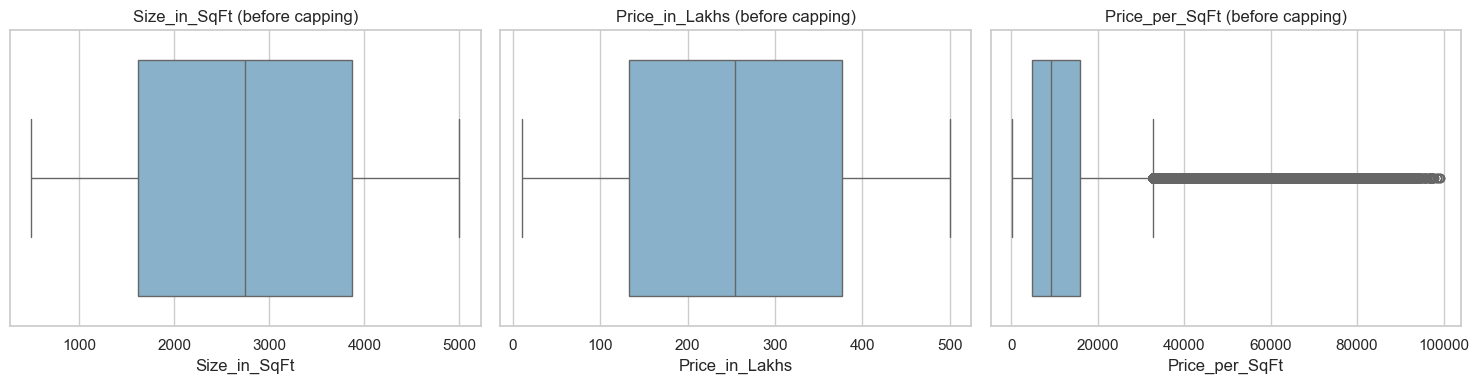

In [9]:
df_pre_cap = df.copy()
out_cols = ["Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt"]

rows = []
for c in out_cols:
    lo, hi = iqr_bounds(df[c], k=1.5)
    n = int(((df[c] < lo) | (df[c] > hi)).sum())
    rows.append({"column": c, "lower_bound": round(lo, 2), "upper_bound": round(hi, 2), "n_outliers": n, "pct": round(100 * n / len(df), 2)})
outlier_report = pd.DataFrame(rows)
display(outlier_report)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, out_cols):
    sns.boxplot(x=df[c], ax=ax, color="#7fb3d5"); ax.set_title(f"{c} (before capping)")
plt.tight_layout(); plt.show()

In [10]:
# Winsorise extreme outliers (3 x IQR) - keeps every row, just limits the extremes
df, cap_bounds = cap_outliers(df, out_cols, k=3.0)
print("Capping bounds:", {k: (round(v[0], 1), round(v[1], 1)) for k, v in cap_bounds.items()})

Capping bounds: {'Size_in_SqFt': (500.0, 10627.0), 'Price_in_Lakhs': (10.0, 1109.9), 'Price_per_SqFt': (202.2, 49541.0)}


## 3. Feature Engineering & Targets

New features: `Price_per_SqFt`, `Amenity_Count`, `Transport_Score`, `Parking_Flag`, `Security_Flag`, `Is_Ready`, `Floor_Ratio`,
`School_Density_Score`, `Hospital_Score`, `Infrastructure_Score`, `City_Median_PPSF`, `PPSF_vs_City`.

**Good Investment label (multi-factor score, max 7, threshold >= 4):**

| Rule | Points |
|---|---|
| Price per sq ft <= city median | 2 |
| Price <= city/property-type median | 1 |
| BHK >= 3 | 1 |
| Ready to move | 1 |
| Transport accessibility Medium/High | 1 |
| Infrastructure score >= median | 1 |

**Future price (5 yrs):** `Future = Current x (1 + r)^5` where `r` is feature-based (see the note at the top).

In [11]:
meta = fit_meta(df)
df = engineer_features(df, meta)
df = make_targets(df, meta, seed=RANDOM_STATE)

print("Good Investment class balance:")
print(df["Good_Investment"].value_counts(normalize=True).round(3))
print("\nGrowth rate summary:")
print(df["Annual_Growth_Rate"].describe().round(4))
df[["Price_in_Lakhs", "Price_per_SqFt", "Infrastructure_Score", "Investment_Score", "Good_Investment",
    "Annual_Growth_Rate", "Future_Price_5Y_Lakhs"]].head()

Good Investment class balance:
Good_Investment
1    0.551
0    0.449
Name: proportion, dtype: float64

Growth rate summary:
count    250000.0000
mean          0.0843
std           0.0128
min           0.0407
25%           0.0749
50%           0.0843
75%           0.0936
max           0.1279
Name: Annual_Growth_Rate, dtype: float64


,Price_in_Lakhs,Price_per_SqFt,Infrastructure_Score,Investment_Score,Good_Investment,Annual_Growth_Rate,Future_Price_5Y_Lakhs
0,489.76,10332.489451,0.550000,2,0,0.104386,804.612658
1,195.52,8270.727580,0.538889,4,1,0.076531,282.698147
2,183.79,5046.403075,0.638889,5,1,0.075502,264.470719
3,300.29,10955.490697,0.866667,3,0,0.112143,510.910050
4,182.90,3792.245490,0.605556,6,1,0.062743,247.945339


In [12]:
df.to_csv("data/processed_housing.csv", index=False)
print("Saved cleaned & processed dataset ->", "data/processed_housing.csv", df.shape)

Saved cleaned & processed dataset -> data/processed_housing.csv (250000, 38)


## 4. Exploratory Data Analysis

In [13]:
df["Locality_Label"] = df["City"] + " - " + df["Locality"].astype(str)
sample = df.sample(min(len(df), 20000), random_state=RANDOM_STATE)   # for heavy scatter plots

### Q1-5: Price & Size

**Q1. Distribution of property prices**

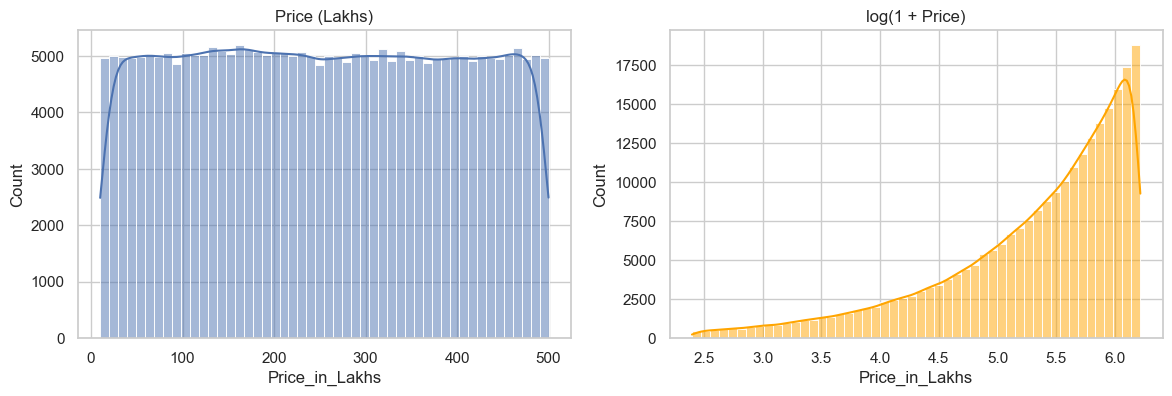

count    250000.00
mean        254.59
std         141.35
min          10.00
25%         132.55
50%         253.87
75%         376.88
max         500.00
Name: Price_in_Lakhs, dtype: float64


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["Price_in_Lakhs"], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Price (Lakhs)")
sns.histplot(np.log1p(df["Price_in_Lakhs"]), bins=50, kde=True, ax=ax[1], color="orange"); ax[1].set_title("log(1 + Price)")
plt.show()
print(df["Price_in_Lakhs"].describe().round(2))

**Q2. Distribution of property sizes**

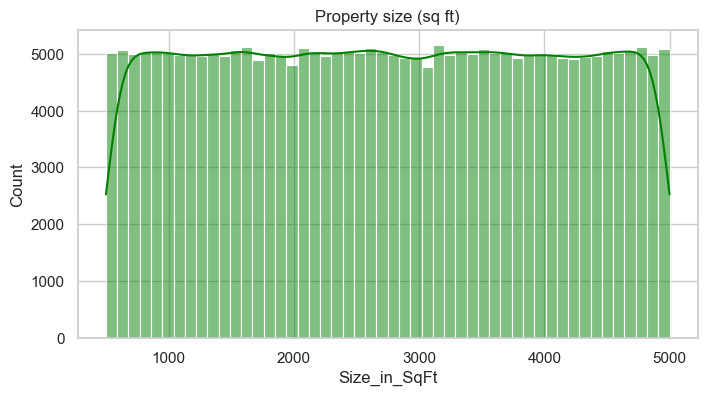

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(df["Size_in_SqFt"], bins=50, kde=True, color="green")
plt.title("Property size (sq ft)"); plt.show()

**Q3. Price per sq ft by property type**

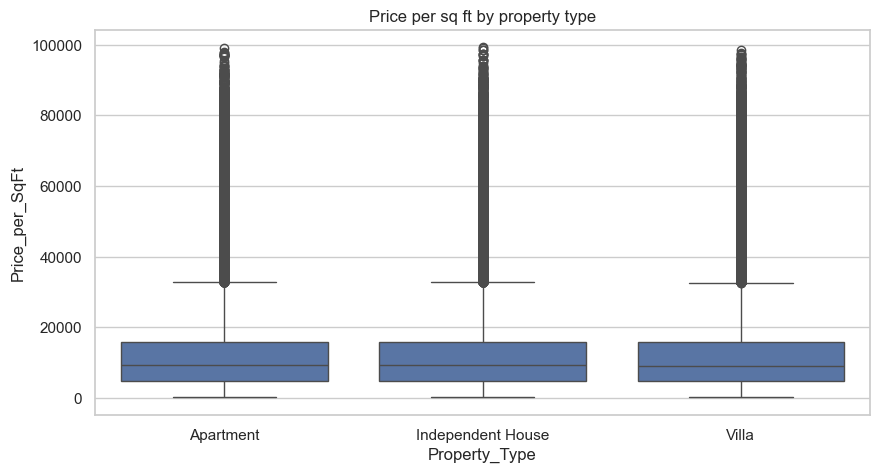

,mean,median,count
Property_Type,,,
Apartment,13047.0,9245.0,82956
Independent House,13102.0,9305.0,83300
Villa,13026.0,9190.0,83744


In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="Property_Type", y="Price_per_SqFt")
plt.title("Price per sq ft by property type"); plt.show()
df.groupby("Property_Type")["Price_per_SqFt"].agg(["mean", "median", "count"]).round(0)

**Q4. Relationship between size and price**

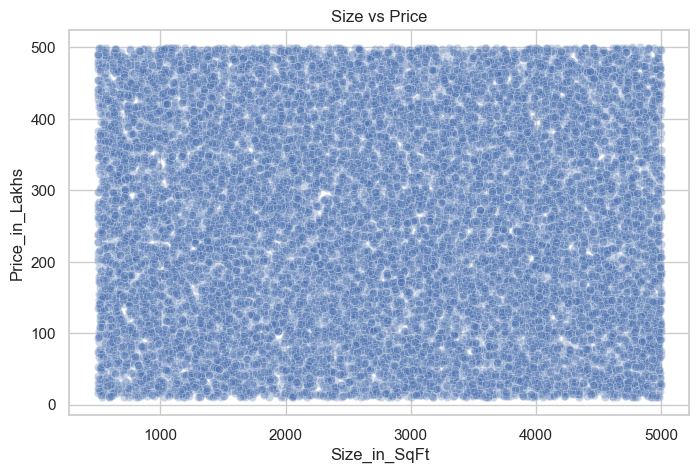

Correlation: -0.003


In [17]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=sample, x="Size_in_SqFt", y="Price_in_Lakhs", alpha=0.3)
plt.title("Size vs Price"); plt.show()
print("Correlation:", round(df["Size_in_SqFt"].corr(df["Price_in_Lakhs"]), 3))

**Q5. Outliers in price per sq ft and size** (counts measured *before* capping)

,column,lower_bound,upper_bound,n_outliers,pct
0,Size_in_SqFt,-1753.50,7250.50,0,0.00
1,Price_in_Lakhs,-233.94,743.38,0,0.00
2,Price_per_SqFt,-11973.98,32764.21,19723,7.89


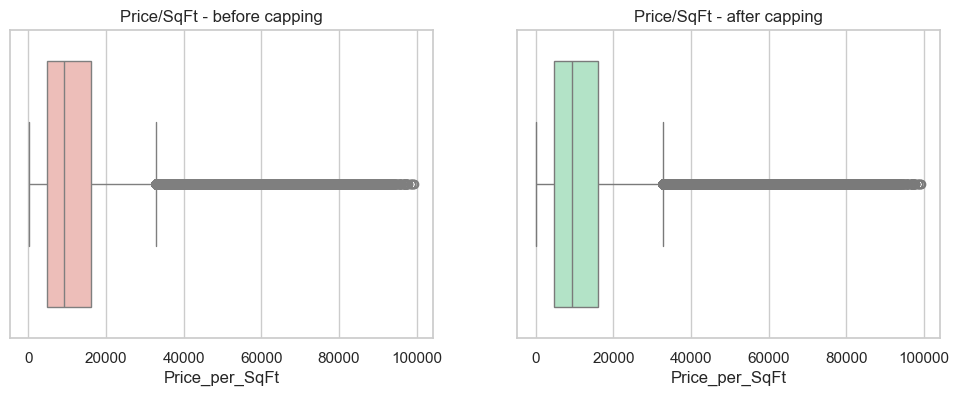

In [18]:
display(outlier_report)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_pre_cap["Price_per_SqFt"], ax=axes[0], color="#f5b7b1"); axes[0].set_title("Price/SqFt - before capping")
sns.boxplot(x=df["Price_per_SqFt"], ax=axes[1], color="#abebc6");          axes[1].set_title("Price/SqFt - after capping")
plt.show()

### Q6-10: Location-based

**Q6. Average price per sq ft by state**

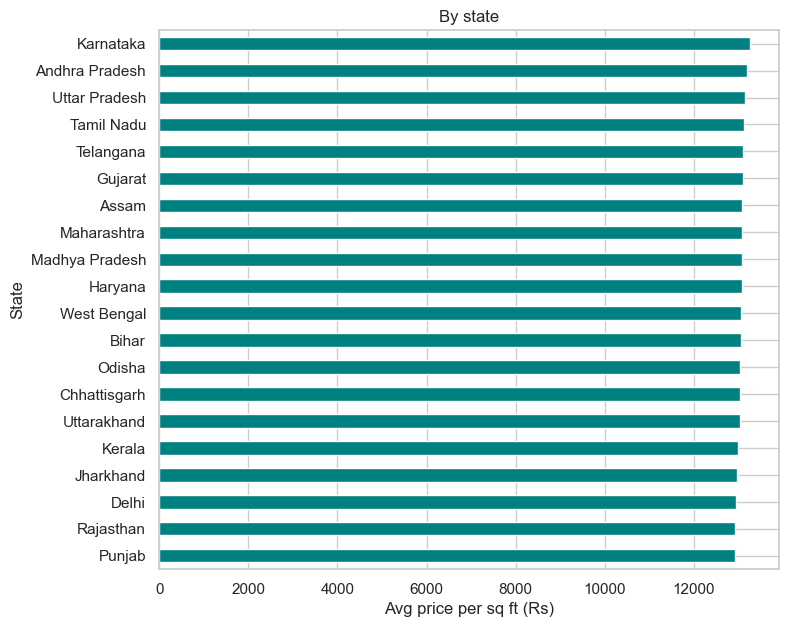

In [19]:
s = df.groupby("State")["Price_per_SqFt"].mean().sort_values()
s.plot(kind="barh", figsize=(8, max(4, len(s) * 0.35)), color="teal")
plt.xlabel("Avg price per sq ft (Rs)"); plt.title("By state"); plt.show()

**Q7. Average property price by city** (also answers *'Price trends by city'*)

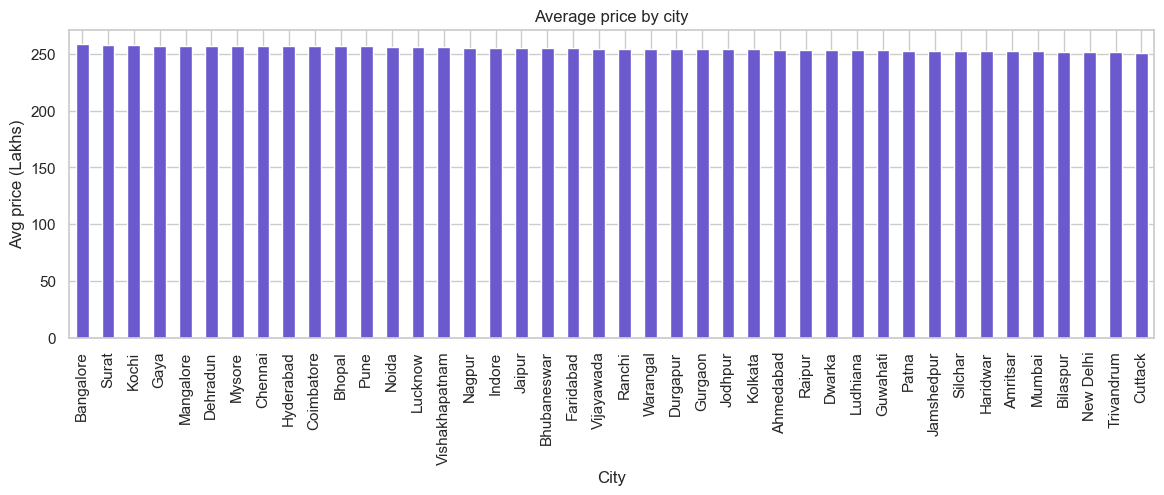

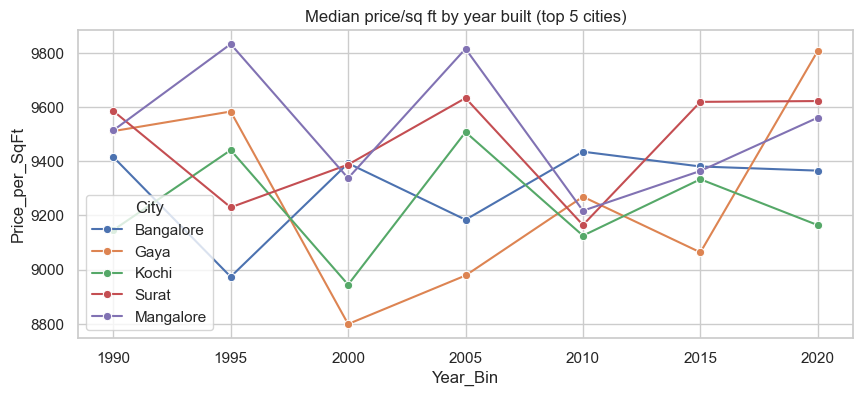

In [20]:
c = df.groupby("City")["Price_in_Lakhs"].mean().sort_values(ascending=False)
c.plot(kind="bar", figsize=(14, 4), color="slateblue"); plt.ylabel("Avg price (Lakhs)"); plt.title("Average price by city"); plt.show()

# price trend by construction year for the 5 priciest cities
top_cities = c.head(5).index
t = df[df["City"].isin(top_cities)].copy()
t["Year_Bin"] = (t["Year_Built"] // 5) * 5
plt.figure(figsize=(10, 4))
sns.lineplot(data=t, x="Year_Bin", y="Price_per_SqFt", hue="City", estimator="median", errorbar=None, marker="o")
plt.title("Median price/sq ft by year built (top 5 cities)"); plt.show()

**Q8. Median age of properties by locality**

Youngest localities:


,median_age
Locality_Label,
Vishakhapatnam - Locality_133,3.0
Hyderabad - Locality_26,3.0
Mysore - Locality_308,3.0
Raipur - Locality_112,4.0
Pune - Locality_148,4.0
Bilaspur - Locality_215,4.0
Nagpur - Locality_185,4.0
Pune - Locality_49,4.0
Nagpur - Locality_403,4.0


Oldest localities:


,median_age
Locality_Label,
Mangalore - Locality_481,33.0
Bangalore - Locality_331,33.0
Nagpur - Locality_426,33.0
Mangalore - Locality_344,33.0
Jaipur - Locality_249,33.0
Jamshedpur - Locality_179,33.0
Mumbai - Locality_349,34.0
Mysore - Locality_70,34.0
Hyderabad - Locality_356,34.0


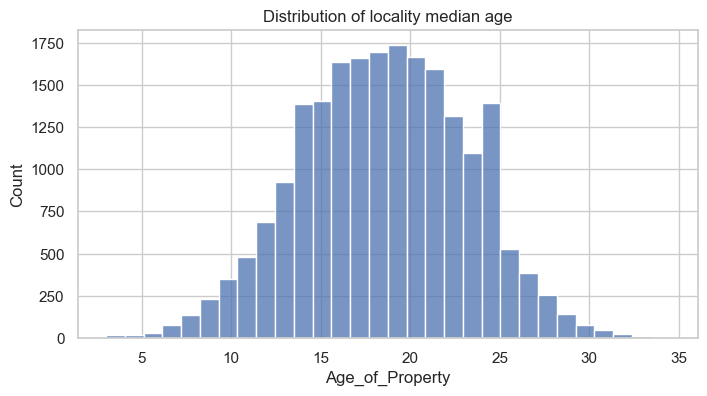

In [21]:
age = df.groupby("Locality_Label")["Age_of_Property"].median().sort_values()
print("Youngest localities:"); display(age.head(10).to_frame("median_age"))
print("Oldest localities:");   display(age.tail(10).to_frame("median_age"))
plt.figure(figsize=(8, 4)); sns.histplot(age, bins=30); plt.title("Distribution of locality median age"); plt.show()

**Q9. BHK distribution across cities**

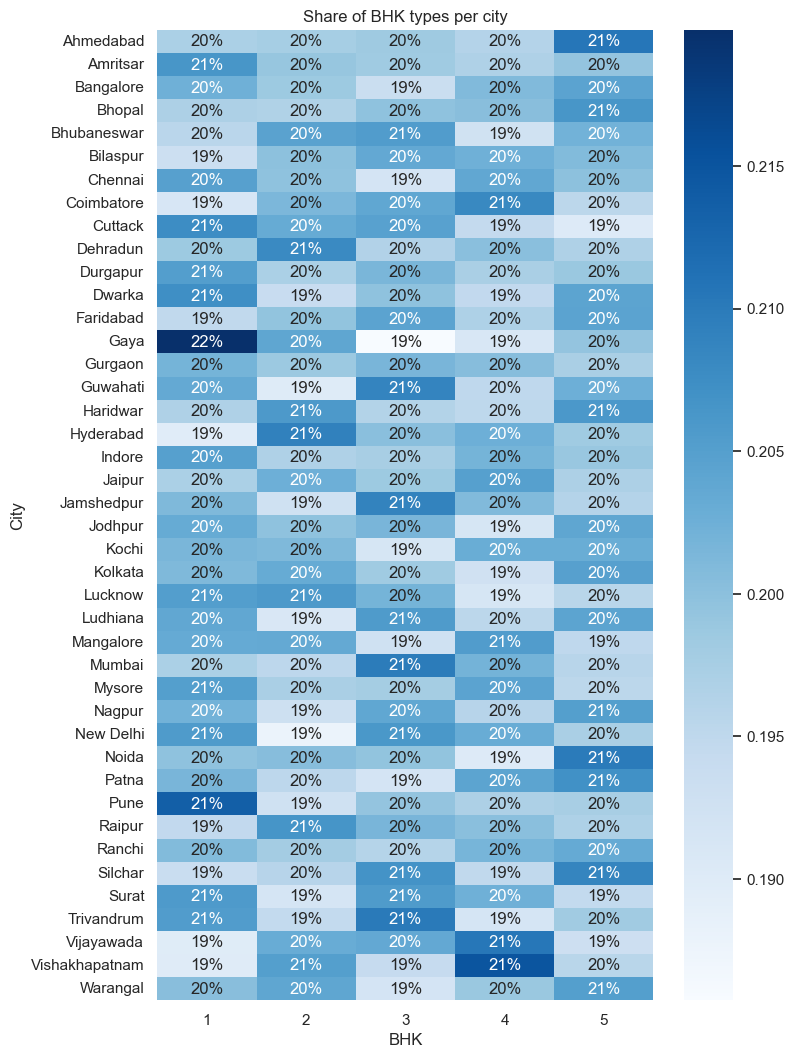

In [22]:
ct = pd.crosstab(df["City"], df["BHK"], normalize="index")
plt.figure(figsize=(8, max(5, len(ct) * 0.3)))
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Blues"); plt.title("Share of BHK types per city"); plt.show()

**Q10. Price trends for the top 5 most expensive localities**

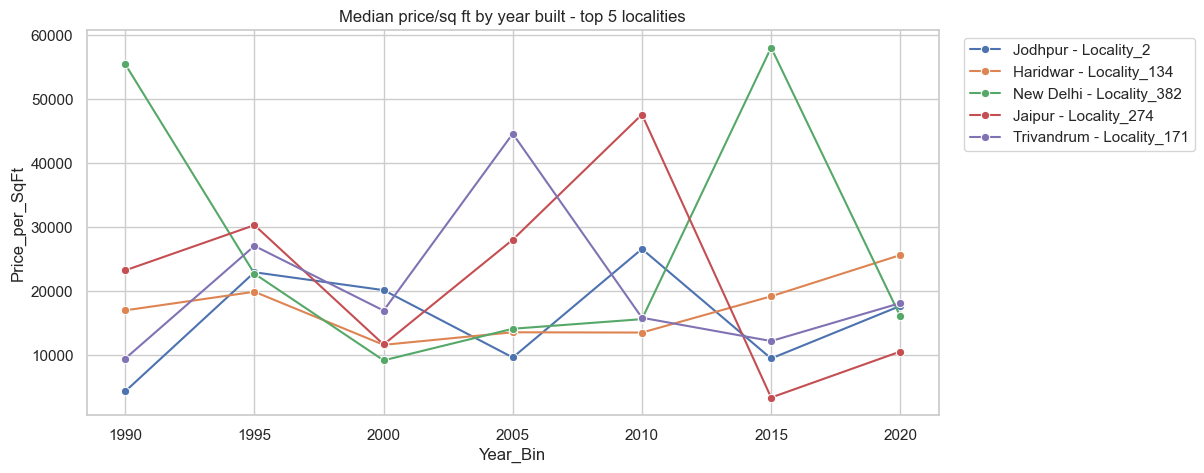

In [23]:
cnt = df["Locality_Label"].value_counts()
valid = cnt[cnt >= 20].index
top5 = (df[df["Locality_Label"].isin(valid)].groupby("Locality_Label")["Price_per_SqFt"].median()
        .sort_values(ascending=False).head(5).index)
t = df[df["Locality_Label"].isin(top5)].copy()
t["Year_Bin"] = (t["Year_Built"] // 5) * 5
plt.figure(figsize=(11, 5))
sns.lineplot(data=t, x="Year_Bin", y="Price_per_SqFt", hue="Locality_Label", estimator="median", errorbar=None, marker="o")
plt.title("Median price/sq ft by year built - top 5 localities"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.show()

### Q11-15: Feature relationships

**Q11. Correlation between numeric features**

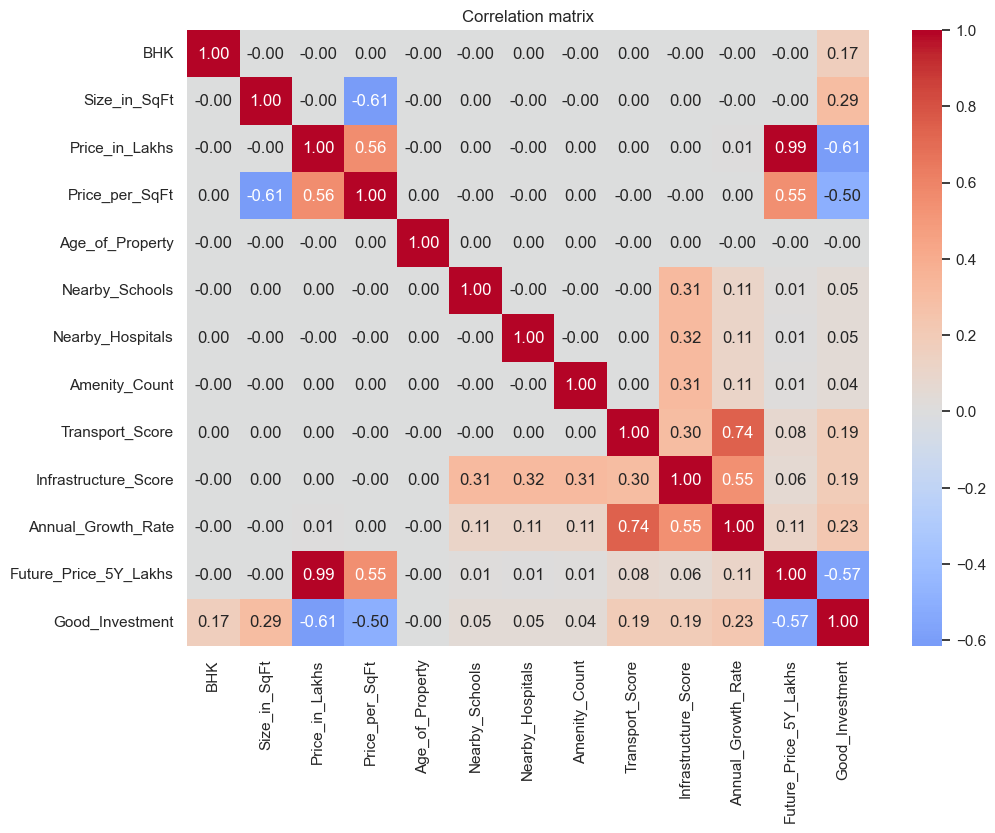

In [24]:
corr_cols = ["BHK", "Size_in_SqFt", "Price_in_Lakhs", "Price_per_SqFt", "Age_of_Property", "Nearby_Schools",
             "Nearby_Hospitals", "Amenity_Count", "Transport_Score", "Infrastructure_Score",
             "Annual_Growth_Rate", "Future_Price_5Y_Lakhs", "Good_Investment"]
plt.figure(figsize=(11, 8))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

**Q12. Nearby schools vs price per sq ft**

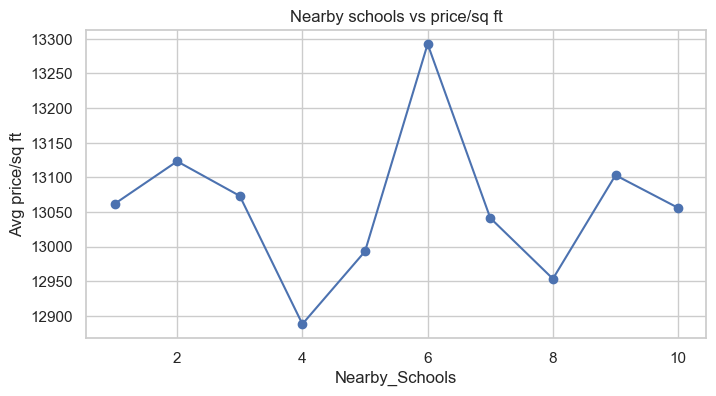

Correlation: -0.0


In [25]:
g = df.groupby("Nearby_Schools")["Price_per_SqFt"].mean()
g.plot(marker="o", figsize=(8, 4)); plt.ylabel("Avg price/sq ft"); plt.title("Nearby schools vs price/sq ft"); plt.show()
print("Correlation:", round(df["Nearby_Schools"].corr(df["Price_per_SqFt"]), 3))

**Q13. Nearby hospitals vs price per sq ft**

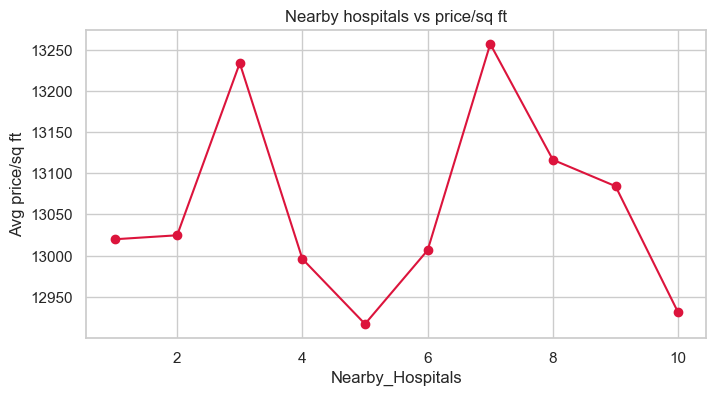

Correlation: -0.0


In [26]:
g = df.groupby("Nearby_Hospitals")["Price_per_SqFt"].mean()
g.plot(marker="o", color="crimson", figsize=(8, 4)); plt.ylabel("Avg price/sq ft"); plt.title("Nearby hospitals vs price/sq ft"); plt.show()
print("Correlation:", round(df["Nearby_Hospitals"].corr(df["Price_per_SqFt"]), 3))

**Q14. Price by furnished status**

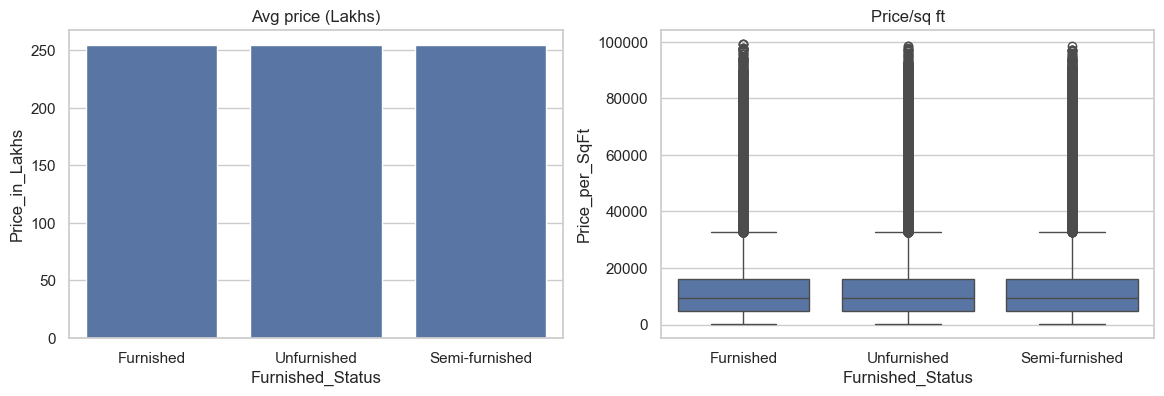

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=df, x="Furnished_Status", y="Price_in_Lakhs", ax=ax[0], errorbar=None); ax[0].set_title("Avg price (Lakhs)")
sns.boxplot(data=df, x="Furnished_Status", y="Price_per_SqFt", ax=ax[1]); ax[1].set_title("Price/sq ft")
plt.show()

**Q15. Price per sq ft by facing direction**

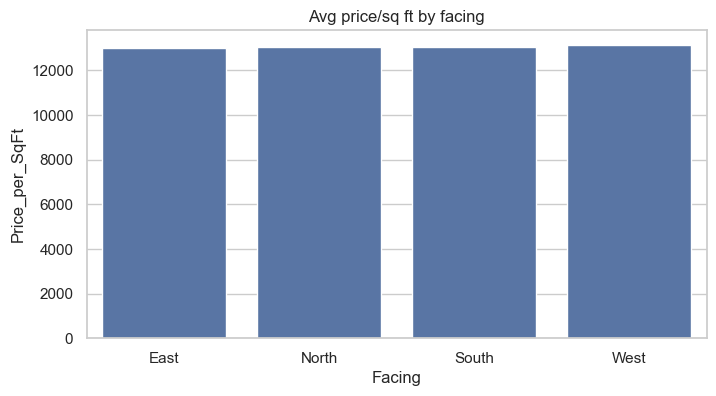

In [28]:
plt.figure(figsize=(8, 4))
sns.barplot(data=df, x="Facing", y="Price_per_SqFt", errorbar=None, order=df.groupby("Facing")["Price_per_SqFt"].mean().sort_values().index)
plt.title("Avg price/sq ft by facing"); plt.show()

### Q16-20: Investment / Amenities / Ownership

**Q16. Properties per owner type**

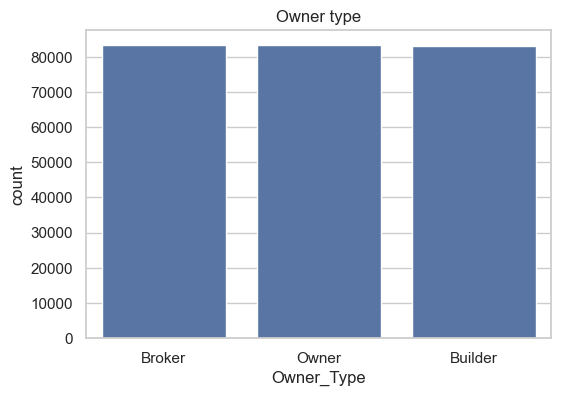

In [29]:
plt.figure(figsize=(6, 4)); sns.countplot(data=df, x="Owner_Type", order=df["Owner_Type"].value_counts().index); plt.title("Owner type"); plt.show()

**Q17. Properties per availability status**

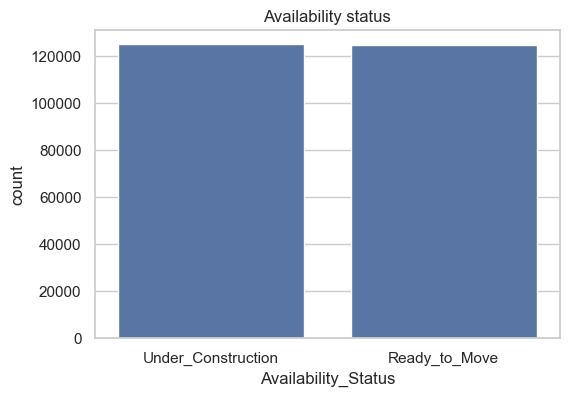

In [30]:
plt.figure(figsize=(6, 4)); sns.countplot(data=df, x="Availability_Status", order=df["Availability_Status"].value_counts().index); plt.title("Availability status"); plt.show()

**Q18. Does parking space affect price?**

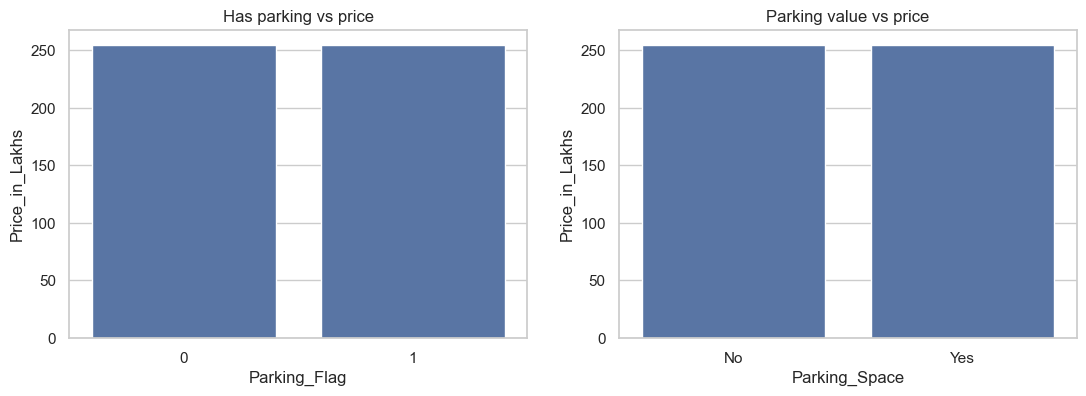

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x="Parking_Flag", y="Price_in_Lakhs", ax=ax[0], errorbar=None); ax[0].set_title("Has parking vs price")
sns.barplot(data=df, x="Parking_Space", y="Price_in_Lakhs", ax=ax[1], errorbar=None); ax[1].set_title("Parking value vs price")
plt.show()

**Q19. How do amenities affect price per sq ft?**

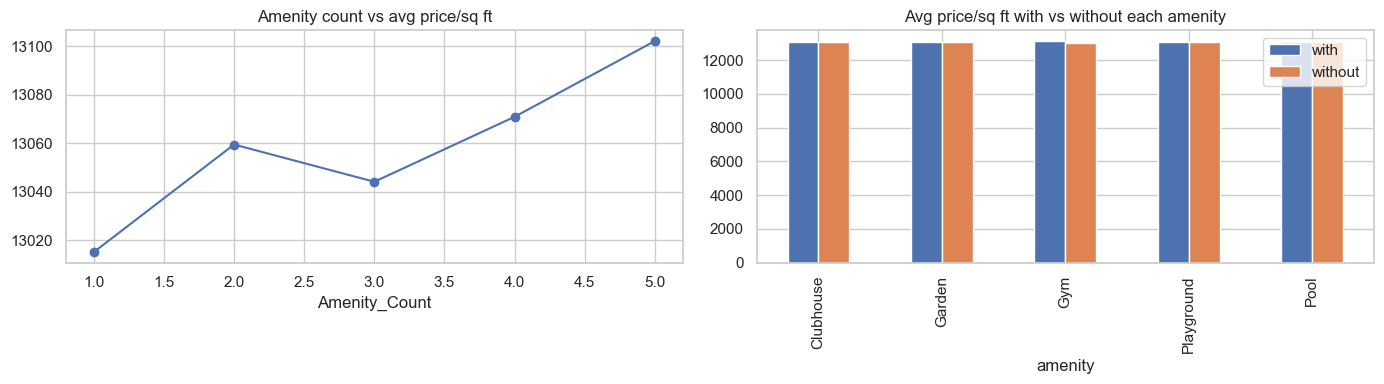

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("Amenity_Count")["Price_per_SqFt"].mean().plot(marker="o", ax=ax[0]); ax[0].set_title("Amenity count vs avg price/sq ft")

rows = []
for a in meta["amenity_options"]:
    has = df["Amenities"].astype(str).str.contains(a, regex=False)
    rows.append({"amenity": a, "with": df.loc[has, "Price_per_SqFt"].mean(), "without": df.loc[~has, "Price_per_SqFt"].mean()})
am = pd.DataFrame(rows).set_index("amenity")
am.plot(kind="bar", ax=ax[1]); ax[1].set_title("Avg price/sq ft with vs without each amenity")
plt.tight_layout(); plt.show()

**Q20. Public transport accessibility vs price per sq ft & investment potential**

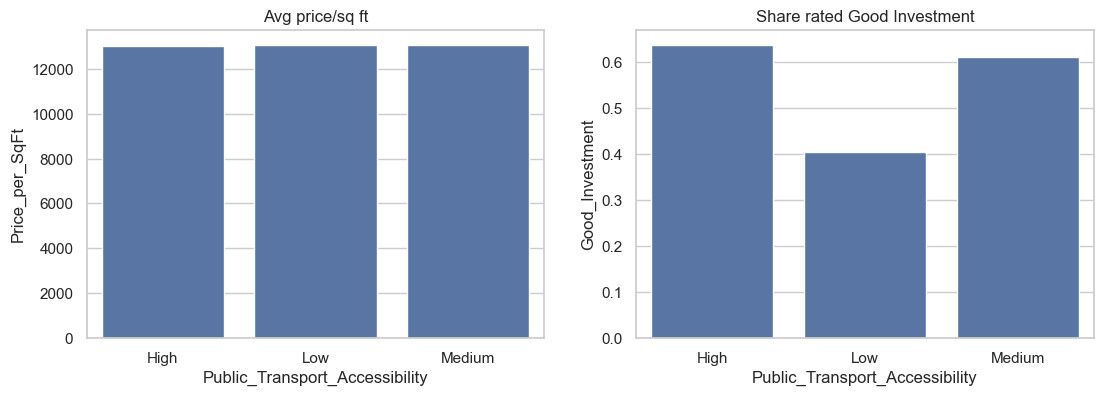

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Price_per_SqFt", ax=ax[0], errorbar=None); ax[0].set_title("Avg price/sq ft")
sns.barplot(data=df, x="Public_Transport_Accessibility", y="Good_Investment", ax=ax[1], errorbar=None); ax[1].set_title("Share rated Good Investment")
plt.show()

### Extra: Infrastructure score vs resale value & investment quality
(The dataset has no crime-rate column, so infrastructure is the proxy for neighbourhood quality.)

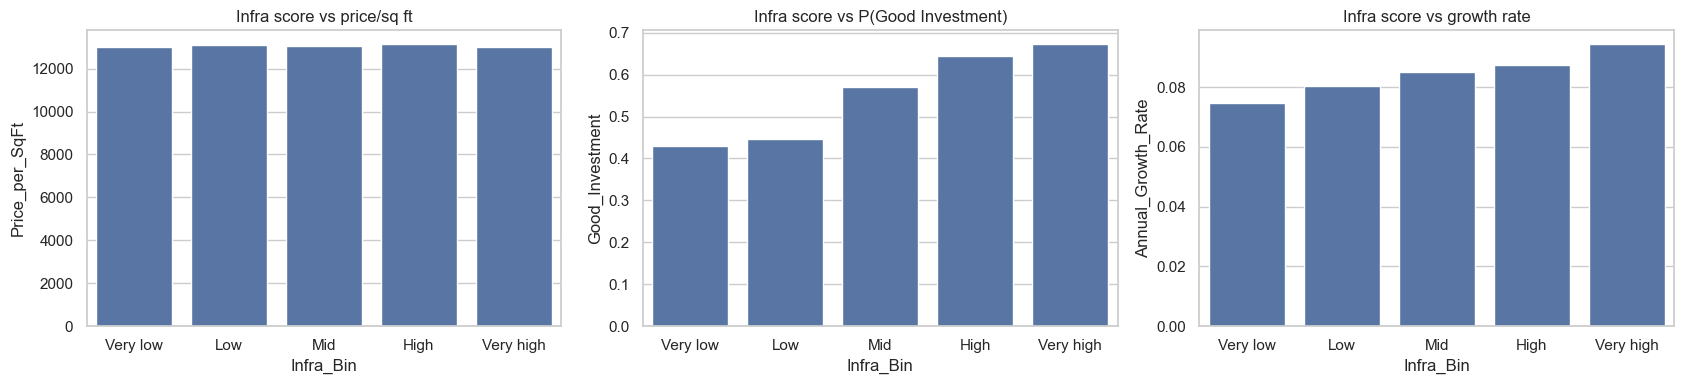

In [34]:
df["Infra_Bin"] = pd.qcut(df["Infrastructure_Score"], 5, labels=["Very low", "Low", "Mid", "High", "Very high"])
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.barplot(data=df, x="Infra_Bin", y="Price_per_SqFt", ax=ax[0], errorbar=None); ax[0].set_title("Infra score vs price/sq ft")
sns.barplot(data=df, x="Infra_Bin", y="Good_Investment", ax=ax[1], errorbar=None); ax[1].set_title("Infra score vs P(Good Investment)")
sns.barplot(data=df, x="Infra_Bin", y="Annual_Growth_Rate", ax=ax[2], errorbar=None); ax[2].set_title("Infra score vs growth rate")
plt.tight_layout(); plt.show()
df = df.drop(columns="Infra_Bin")

## 5. Modelling with MLflow

* Numeric features -> `StandardScaler`; categorical -> `OneHotEncoder`.
* Classification target: `Good_Investment`; regression target: `Future_Price_5Y_Lakhs`.
* Every model is logged to MLflow (params, metrics, plots, model); the best of each task is registered.

> **Leakage caveat:** the `Good_Investment` label is derived from some of the input features, so classification
> scores will be very high. For a real project, label using *future* returns (e.g. realised appreciation) instead.

In [35]:
X = df[ALL_FEATURES]
y_clf = df["Good_Investment"]
y_reg = df["Future_Price_5Y_Lakhs"]

X_train, X_test, yc_train, yc_test, yr_train, yr_test = train_test_split(
    X, y_clf, y_reg, test_size=0.2, random_state=RANDOM_STATE, stratify=y_clf)
print("Train:", X_train.shape, " Test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), NUM_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATURES),
    ])

mlflow.set_tracking_uri("sqlite:///mlflow.db")      # local DB (supports the Model Registry)

def log_sk_model(model, name="model"):
    # cloudpickle avoids skops "untrusted type" errors for tree models in newer MLflow
    try:
        mlflow.sklearn.log_model(model, name=name, serialization_format="cloudpickle")            # MLflow >= 3
    except TypeError:
        mlflow.sklearn.log_model(model, artifact_path=name, serialization_format="cloudpickle")   # MLflow 2.x

def simple_params(est):
    return {k: v for k, v in est.get_params().items() if isinstance(v, (int, float, str, bool))}

Train: (200000, 27)  Test: (50000, 27)


### 5.1 Classification - *Is this a Good Investment?*

In [ ]:
mlflow.set_experiment("RealEstate_GoodInvestment_Classification")

clf_models = {
    "LogisticRegression": LogisticRegression(max_iter=800),
    "RandomForest": RandomForestClassifier(n_estimators=80, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=150, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
                             eval_metric="logloss", n_jobs=-1, random_state=RANDOM_STATE),
}

clf_results, clf_fitted = {}, {}
for name, est in clf_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", est)])
    with mlflow.start_run(run_name=name) as run:
        pipe.fit(X_train, yc_train)
        pred = pipe.predict(X_test)
        proba = pipe.predict_proba(X_test)[:, 1]
        m = {
            "accuracy": accuracy_score(yc_test, pred),
            "precision": precision_score(yc_test, pred),
            "recall": recall_score(yc_test, pred),
            "f1": f1_score(yc_test, pred),
            "roc_auc": roc_auc_score(yc_test, proba),
        }
        cm = confusion_matrix(yc_test, pred)

        mlflow.log_params(simple_params(est))
        mlflow.log_param("model_name", name)
        mlflow.log_metrics(m)
        fig, ax = plt.subplots(figsize=(4, 3.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax, xticklabels=["Not good", "Good"], yticklabels=["Not good", "Good"])
        ax.set_title(f"{name} - confusion matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
        mlflow.log_figure(fig, "confusion_matrix.png"); plt.close(fig)
        log_sk_model(pipe, "model")

        clf_results[name] = {**m, "run_id": run.info.run_id, "confusion_matrix": cm.tolist()}
        clf_fitted[name] = pipe
    print(f"{name:20s}", {k: round(v, 4) for k, v in m.items()})

clf_table = pd.DataFrame(clf_results).T.drop(columns=["run_id", "confusion_matrix"]).astype(float).round(4)
best_clf_name = clf_table["f1"].idxmax()
print("\nBest classifier:", best_clf_name)
clf_table

2026/11/03 13:21:24 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/03 13:21:24 INFO mlflow.store.db.utils: Updating database tables
2026/11/03 13:21:32 INFO mlflow.tracking.fluent: Experiment with name 'RealEstate_GoodInvestment_Classification' does not exist. Creating a new experiment.
2026/11/03 13:21:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


LogisticRegression   {'accuracy': 0.8914, 'precision': 0.9004, 'recall': 0.9026, 'f1': 0.9015, 'roc_auc': 0.9615}


### 5.2 Regression - *Estimated price after 5 years*

In [37]:
mlflow.set_experiment("RealEstate_FuturePrice_Regression")

reg_models = {
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBRegressor(n_estimators=400, max_depth=6, learning_rate=0.08, subsample=0.9, colsample_bytree=0.9,
                            n_jobs=-1, random_state=RANDOM_STATE),
}

reg_results, reg_fitted = {}, {}
for name, est in reg_models.items():
    pipe = Pipeline([("prep", make_preprocessor()), ("model", est)])
    with mlflow.start_run(run_name=name) as run:
        pipe.fit(X_train, yr_train)
        pred = pipe.predict(X_test)
        m = {
            "rmse": float(np.sqrt(mean_squared_error(yr_test, pred))),
            "mae": float(mean_absolute_error(yr_test, pred)),
            "r2": float(r2_score(yr_test, pred)),
        }
        mlflow.log_params(simple_params(est))
        mlflow.log_param("model_name", name)
        mlflow.log_metrics(m)
        idx = np.random.RandomState(0).choice(len(pred), size=min(3000, len(pred)), replace=False)
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ax.scatter(np.asarray(yr_test)[idx], pred[idx], s=5, alpha=0.4)
        lim = [0, max(np.asarray(yr_test).max(), pred.max())]
        ax.plot(lim, lim, "r--"); ax.set_xlabel("Actual (Lakhs)"); ax.set_ylabel("Predicted (Lakhs)"); ax.set_title(f"{name}")
        mlflow.log_figure(fig, "pred_vs_actual.png"); plt.close(fig)
        log_sk_model(pipe, "model")

        reg_results[name] = {**m, "run_id": run.info.run_id}
        reg_fitted[name] = pipe
    print(f"{name:20s}", {k: round(v, 4) for k, v in m.items()})

reg_table = pd.DataFrame(reg_results).T.drop(columns=["run_id"]).astype(float).round(4)
best_reg_name = reg_table["rmse"].idxmin()
print("\nBest regressor:", best_reg_name)
reg_table

2026/11/03 13:25:40 INFO mlflow.tracking.fluent: Experiment with name 'RealEstate_FuturePrice_Regression' does not exist. Creating a new experiment.
2026/11/03 13:25:44 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Ridge                {'rmse': 14.1064, 'mae': 10.7026, 'r2': 0.9957}


2026/11/03 13:29:49 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


RandomForest         {'rmse': 8.989, 'mae': 6.3475, 'r2': 0.9982}


2026/11/03 13:30:57 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


XGBoost              {'rmse': 8.2936, 'mae': 5.8215, 'r2': 0.9985}

Best regressor: XGBoost


,rmse,mae,r2
Ridge,14.1064,10.7026,0.9957
RandomForest,8.9890,6.3475,0.9982
XGBoost,8.2936,5.8215,0.9985


### 5.3 Register the best models in the MLflow Model Registry

In [38]:
for model_name, run_id in [("RealEstate_GoodInvestment_Classifier", clf_results[best_clf_name]["run_id"]),
                           ("RealEstate_FuturePrice_Regressor", reg_results[best_reg_name]["run_id"])]:
    try:
        v = mlflow.register_model(f"runs:/{run_id}/model", model_name)
        print("Registered:", model_name, "version", v.version)
    except Exception as e:
        print("Registry step skipped for", model_name, "->", e)
# Browse experiments with:  mlflow ui --backend-store-uri sqlite:///mlflow.db

Successfully registered model 'RealEstate_GoodInvestment_Classifier'.
2026/11/03 13:33:24 WARNING mlflow.tracking._model_registry.fluent: Run with id b39ac0882e1d484a8dffa9a01840f2cb has no artifacts at artifact path 'model', registering model based on models:/m-d4803d44522d4a818480b71acb220e4e instead
Created version '1' of model 'RealEstate_GoodInvestment_Classifier'.
Successfully registered model 'RealEstate_FuturePrice_Regressor'.
2026/11/03 13:33:24 WARNING mlflow.tracking._model_registry.fluent: Run with id d0f2fc54764141ba98776eb37187f59d has no artifacts at artifact path 'model', registering model based on models:/m-57f67847eb9c483681cb0aabc71f89b2 instead
Created version '1' of model 'RealEstate_FuturePrice_Regressor'.


Registered: RealEstate_GoodInvestment_Classifier version 1
Registered: RealEstate_FuturePrice_Regressor version 1


### 5.4 Feature importance & model confidence

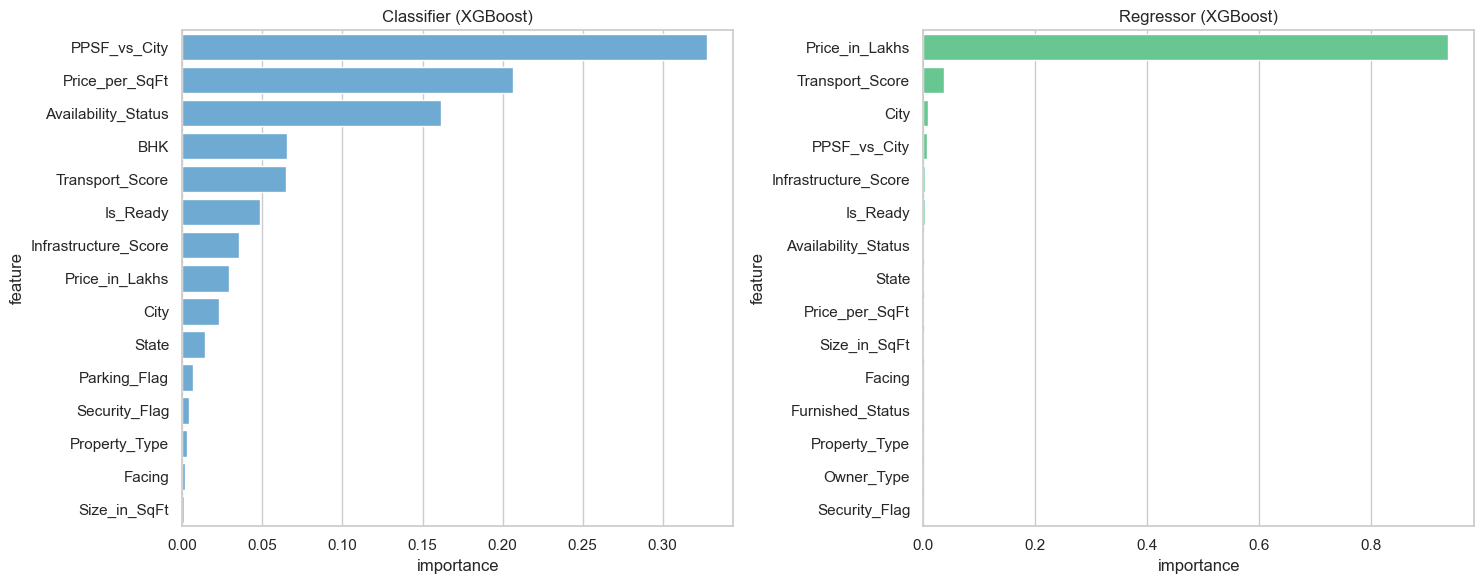

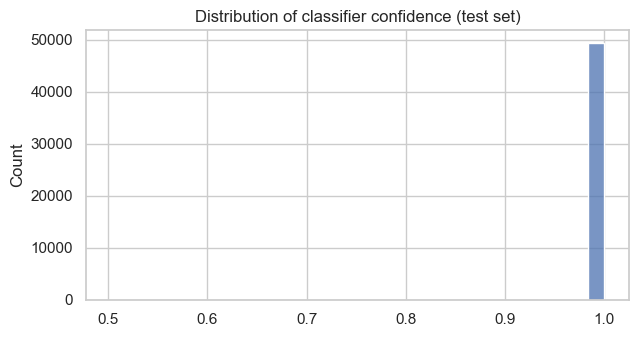

In [39]:
def feature_importance(pipe):
    names = pipe.named_steps["prep"].get_feature_names_out()
    model = pipe.named_steps["model"]
    imp = model.feature_importances_ if hasattr(model, "feature_importances_") else np.abs(model.coef_).ravel()
    def base(n):
        n = n.split("__", 1)[1]
        for c in CAT_FEATURES:
            if n.startswith(c + "_"):
                return c
        return n
    out = pd.DataFrame({"feature": [base(n) for n in names], "importance": imp}).groupby("feature")["importance"].sum()
    return (out / out.sum()).sort_values(ascending=False).reset_index()

clf_imp = feature_importance(clf_fitted[best_clf_name])
reg_imp = feature_importance(reg_fitted[best_reg_name])

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=clf_imp.head(15), y="feature", x="importance", ax=ax[0], color="#5dade2"); ax[0].set_title(f"Classifier ({best_clf_name})")
sns.barplot(data=reg_imp.head(15), y="feature", x="importance", ax=ax[1], color="#58d68d"); ax[1].set_title(f"Regressor ({best_reg_name})")
plt.tight_layout(); plt.show()

# Classification confidence = predicted probability of the predicted class
proba = clf_fitted[best_clf_name].predict_proba(X_test)
conf = proba.max(axis=1)
plt.figure(figsize=(7, 3.5)); sns.histplot(conf, bins=30); plt.title("Distribution of classifier confidence (test set)"); plt.show()

## 6. Save artifacts for the Streamlit app

In [43]:
joblib.dump(clf_fitted[best_clf_name], "models/clf_model.joblib", compress=3)
joblib.dump(reg_fitted[best_reg_name], "models/reg_model.joblib", compress=3)
clf_imp.to_csv("models/clf_importance.csv", index=False)
reg_imp.to_csv("models/reg_importance.csv", index=False)

meta["test_rmse"] = float(reg_results[best_reg_name]["rmse"])
with open("models/meta.json", "w") as f:
    json.dump(meta, f, indent=2)

metrics = {
    "best_clf": best_clf_name, "best_reg": best_reg_name,
    "classification": {k: {m: v for m, v in d.items() if m not in ("run_id", "confusion_matrix")} for k, d in clf_results.items()},
    "regression": {k: {m: v for m, v in d.items() if m != "run_id"} for k, d in reg_results.items()},
    "confusion_matrix": clf_results[best_clf_name]["confusion_matrix"],
}
with open("models/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("Saved:", sorted(os.listdir("models")))

Saved: ['clf_importance.csv', 'clf_model.joblib', 'meta.json', 'metrics.json', 'reg_importance.csv', 'reg_model.joblib']


### Smoke test - predict for one new property (same logic the Streamlit app uses)

In [44]:
clf = joblib.load("models/clf_model.joblib"); reg = joblib.load("models/reg_model.joblib")
with open("models/meta.json") as f:
    meta_loaded = json.load(f)

city = df["City"].iloc[0]
new = pd.DataFrame([{
    "State": meta_loaded["city_state"][city], "City": city, "Locality": "Demo", "Property_Type": df["Property_Type"].iloc[0],
    "BHK": 3, "Size_in_SqFt": 1500, "Price_in_Lakhs": 110, "Price_per_SqFt": 110 * 1e5 / 1500,
    "Year_Built": 2018, "Furnished_Status": df["Furnished_Status"].iloc[0], "Floor_No": 5, "Total_Floors": 12,
    "Age_of_Property": CURRENT_YEAR - 2018, "Nearby_Schools": 6, "Nearby_Hospitals": 5,
    "Public_Transport_Accessibility": "High", "Parking_Space": 1, "Security": "Yes",
    "Amenities": ", ".join(meta_loaded["amenity_options"][:3]), "Facing": df["Facing"].iloc[0],
    "Owner_Type": df["Owner_Type"].iloc[0], "Availability_Status": df["Availability_Status"].iloc[0],
}])
xn = engineer_features(new, meta_loaded)[ALL_FEATURES]
p = clf.predict_proba(xn)[0]
print(f"Good investment? {'YES' if p[1] >= 0.5 else 'NO'}  (P(good) = {p[1]:.2%})")
print(f"Estimated price after 5 years: Rs {reg.predict(xn)[0]:.1f} Lakhs (today: 110 Lakhs)")

Good investment? YES  (P(good) = 100.00%)
Estimated price after 5 years: Rs 184.7 Lakhs (today: 110 Lakhs)
